# Preload Cloudinary 

When using Cloudinary, there is this [auto-upload](https://cloudinary.com/documentation/migration#lazy_migration_with_auto_upload) feature that will just pull videos of the origin when there is a request for it. 

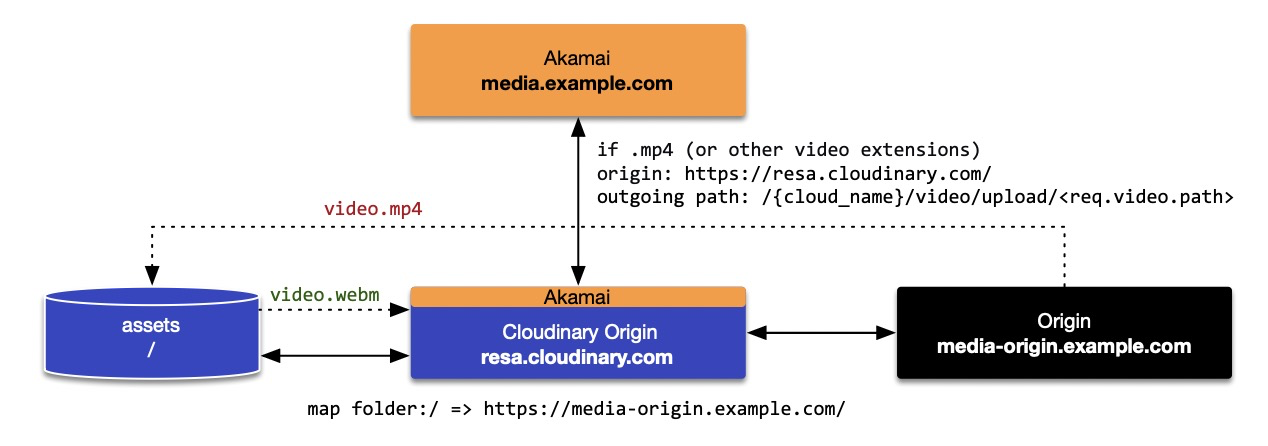

But since all video URLs are available in Akamai Image and Video Manager (IVM), why not retrieve them from IVM via an API call and pull them into Cloudinary assets database via a `curl` request. When there is a request for a video, the customer doesn't have to wait for this *auto-upload* to happen, that is already done.

When all existing videos are stored in the assets database, customers can choose to upload videos directly into Cloudinary or keep everything as it is, and just keep on using the *auto-upload* feature to automatically pull in new videos into the assets database from the origin.

hallo eric

## Set Up EdgeGrid Session

Let's first set up an EdgeGrid session using information from the `~/.edgerc` file. The correct *section* can be set via `export AKAMAI_EDGEGRID_SECTION=section`; otherwise, `default` is going to be used.

Make sure your API user has the [Reporting API permissions](https://techdocs.akamai.com/reporting/reference/get-started).

This notebook supports the `AccountSwitchKey` option, which can be set via `export AKAMAI_ACCOUNT_SWITCH_KEY="1-2345:A-BCDE"`

In [1]:
import json
import os

import requests
from akamai.edgegrid import EdgeGridAuth, EdgeRc

edgerc_path = os.path.expanduser("~/.edgerc")

if not os.path.exists(edgerc_path):
    raise FileNotFoundError(f"Could not find .edgerc at {edgerc_path}")

section = os.getenv("AKAMAI_EDGEGRID_SECTION", "default")
account_switch_key = os.getenv("AKAMAI_ACCOUNT_SWITCH_KEY")

edgerc = EdgeRc(edgerc_path)
host = edgerc.get(section, "host")

session = requests.Session()
session.auth = EdgeGridAuth.from_edgerc(edgerc, section)
session.headers.update({
    "Accept": "application/json",
    "Content-Type": "application/json",
})

base_url = f"https://{host}"
print(f"EdgeGrid session configured for host: {host}")

if account_switch_key:
    print(f"Using AccountSwitchKey: {account_switch_key}")

EdgeGrid session configured for host: akab-zffdc2nm6rfjyspl-cqrxpsvcy2crfdvc.luna.akamaiapis.net
Using AccountSwitchKey: 1-ZPZJ5N:1-5G3LB


## Reporting API

Now lets use the [Reporting v2 API](https://techdocs.akamai.com/reporting/reference/delivery-ivm-video-urls) to get a list of all videos. Let's store the *hostname* and *path* so `curl` will use the right hostname to pull the video in.

In [2]:
from urllib.parse import urlsplit

report_url = f"{base_url}/reporting-api/v2/reports/delivery/ivm/video-urls/data"

# Mirror the working Paw request format exactly.
params = {
    "timeRange": "LAST_90_DAYS",
}
if account_switch_key:
    params["accountSwitchKey"] = account_switch_key

body = {
    "dimensions": [
      "url"
    ],
    "metrics": [
    "hits2xx"
    ],
    "limit": 10000,
    "sortBys": [
    {
      "name": "hits2xx",
      "sortOrder": "DESCENDING"
    }
    ]
}

response = session.post(report_url, params=params, json=body, timeout=60)

# Some API clients are not provisioned for account switching.
if response.status_code == 401 and "accountSwitchKey" in params:
    try:
        error_payload = response.json()
    except ValueError:
        error_payload = {}

    if error_payload.get("code") == "identity_not_authorized_to_manage_any_context":
        print("Account switch key not allowed for this API client; retrying without accountSwitchKey.")
        params.pop("accountSwitchKey", None)
        response = session.post(report_url, params=params, json=body, timeout=60)

if not response.ok:
    try:
        error_payload = response.json()
    except ValueError:
        error_payload = response.text

    raise RuntimeError(
        "Reporting API request failed: "
        f"{response.status_code} {response.reason}\n"
        f"URL: {response.url}\n"
        f"Details: {json.dumps(error_payload, indent=2) if isinstance(error_payload, dict) else error_payload}"
    )

data = response.json().get("data", [])

# Build list of hostname/path pairs from each reported URL.
video_targets = []
for item in data:
    raw_url = item.get("url", "")
    if not raw_url:
        continue

    if "://" in raw_url:
        parts = urlsplit(raw_url)
        hostname = parts.netloc
        path = parts.path
    else:
        first_slash = raw_url.find("/")
        if first_slash == -1:
            continue
        hostname = raw_url[:first_slash]
        path = raw_url[first_slash:]

    if hostname and path:
        video_targets.append({"hostname": hostname, "path": path})

print(f"Collected {len(video_targets)} hostname/path items")
video_targets[:10]

Account switch key not allowed for this API client; retrying without accountSwitchKey.
Collected 0 hostname/path items


[]

## Now fetch video via Cloudinary

Now that we have that list, just go through the process of requesting these videos via the delivery configuration managed by the customer. So we're following this whole flow from *request => akamai => cloudinary => auto-upload => optimize => akamai => response*

This test is using `MAX_ITEMS` but if you are feeling comfortable, just remove the `[:MAX_ITEMS]` and all images will be pulled into the Cloudinary DAM.

> **note**: We're using Akamai Staging in this example, so the `curl` request is using `--resolve f"{hostname}:443:{STAGING_IP}"` to direct requests to the Akamai Staging platform

In [ ]:
import subprocess

STAGING_IP = "104.103.169.11"
MAX_ITEMS = 15

if not video_targets:
    print("No video targets found. Run Cell 5 first and ensure it returns items.")
    results = []
else:
    sample_targets = video_targets[:MAX_ITEMS]
    print(f"Running HEAD checks for {len(sample_targets)} targets via {STAGING_IP}...")

    results = []
    for i, target in enumerate(sample_targets, start=1):
        hostname = target["hostname"]
        path = target["path"]
        url = f"https://{hostname}{path}"

        # HEAD request with DNS override to Akamai staging.
        cmd = [
            "curl",
            "-I",
            "-s",
            "-D",
            "-",
            "-o",
            "/dev/null",
            "-w",
            "\n__HTTP_CODE__:%{http_code}",
            "--connect-timeout",
            "10",
            "--max-time",
            "20",
            url,
            "--resolve",
            f"{hostname}:443:{STAGING_IP}",
        ]

        proc = subprocess.run(cmd, capture_output=True, text=True)

        if proc.returncode == 0:
            output = proc.stdout
            content_type = ""
            status_code = "000"

            for line in output.splitlines():
                lower_line = line.lower()
                if lower_line.startswith("content-type:"):
                    content_type = line.split(":", 1)[1].strip()
                elif line.startswith("__HTTP_CODE__:"):
                    status_code = line.split(":", 1)[1].strip()
        else:
            status_code = f"CURL_ERROR_{proc.returncode}"
            content_type = ""

        results.append(
            {
                "hostname": hostname,
                "path": path,
                "status_code": status_code,
                "content_type": content_type,
            }
        )
        print(f"{i}/{len(sample_targets)} {hostname}{path} -> {status_code} {content_type}")
        
# results

## Check assets in Cloudinary

You should now see new videos in your Cloudinary assets with a little blue dot.
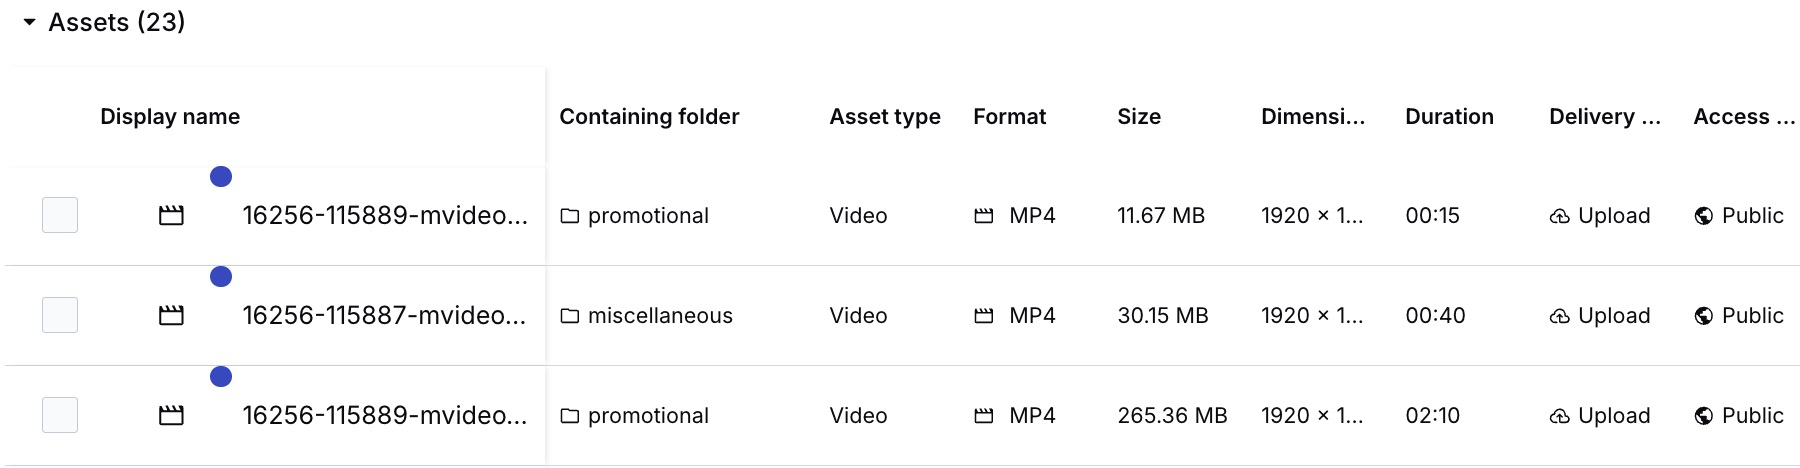